# Support Vector Machines: from geometry to the trained model

This notebook derives the binary support vector machine from zero. We will not treat the SVM as a black-box classifier: every important equation is derived and then visualized.

We use the label convention

$$
y_i \in \{-1,+1\}, \qquad x_i \in \mathbb{R}^d, \qquad i=1,\ldots,n.
$$

Road map: separating hyperplanes, signed distance, geometric margin, the maximum-margin line, hard-margin primal optimization, Lagrange duality, KKT conditions, support vectors, soft margins and hinge loss, kernels, and final training/prediction.

## 1. What problem does an SVM solve?

A binary classifier receives a point $x$ and predicts one of two labels. An SVM learns a hyperplane

$$
f(x)=w^\top x+b=0,$$

where $w\in\mathbb{R}^d$ is normal to the hyperplane and $b\in\mathbb{R}$ is its offset. The classifier is

$$
\hat y(x)=\operatorname{sign}(w^\top x+b).
$$

For $d=2$, the hyperplane is a line. For $d=3$, it is a plane. In general it is a $(d-1)$-dimensional hyperplane.

The central SVM idea is not merely to find *a* separating hyperplane. If many lines separate the classes, choose the one with the largest safety buffer, called the **margin**.

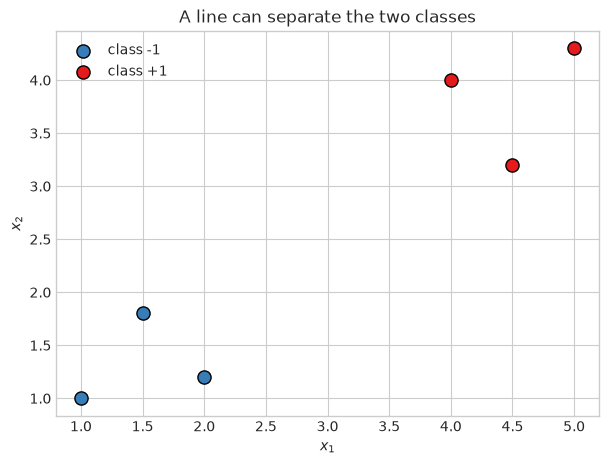

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from scipy.optimize import minimize

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(7)

X_demo = np.array([[1.0, 1.0], [1.5, 1.8], [2.0, 1.2],
                   [4.0, 4.0], [4.5, 3.2], [5.0, 4.3]])
y_demo = np.array([-1, -1, -1, 1, 1, 1])

fig, ax = plt.subplots(figsize=(7, 5))
for label, color, name in [(-1, "#377eb8", "class -1"), (1, "#e41a1c", "class +1")]:
    pts = X_demo[y_demo == label]
    ax.scatter(pts[:, 0], pts[:, 1], s=90, c=color, label=name, edgecolor="black")
ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", title="A line can separate the two classes")
ax.legend(); plt.show()

## 2. A hyperplane is a flat surface, and $w$ points straight out of it

Start with the line

$$
w^\top x+b=0.
$$

Choose two points on this line and call them $x_A$ and $x_B$. Because both points are on the line,

$$
w^\top x_A+b=0,
\qquad
w^\top x_B+b=0.
$$

Subtract the first equation from the second:

$$
w^\top x_B-w^\top x_A=0.
$$

Using the distributive rule,

$$
\boxed{w^\top(x_B-x_A)=0.}
$$

The vector

$$
d_{AB}=x_B-x_A
$$

runs along the line. The dot product being zero means that $w$ is perpendicular to $d_{AB}$. This is the key geometric fact: **$w$ points across the line, while $x_B-x_A$ points along the line.**

## 3. Distance from a point to the line: use the unit normal

The vector $w$ may be long or short, so first turn it into a unit vector in the same direction:

$$
\boxed{n=\frac{w}{\|w\|}},
\qquad
\|n\|=1.
$$

The line equation $w^\top x+b=0$ can be divided by $\|w\|$:

$$
n^\top x+\frac{b}{\|w\|}=0.
$$

For any point $x$, the scalar

$$
\boxed{d_{\pm}(x)=n^\top x+\frac{b}{\|w\|}=\frac{w^\top x+b}{\|w\|}}
$$

is its signed distance from the line. Why? The dot product with the unit normal measures exactly how far we move in the perpendicular direction. The absolute distance is $|d_{\pm}(x)|$.

If $d_{\pm}(x)>0$, the point lies in the direction of $w$ from the line. If $d_{\pm}(x)<0$, it lies in the opposite direction. The shortest path to the line is always parallel to $w$, because every direction along the line is perpendicular to this shortest path.

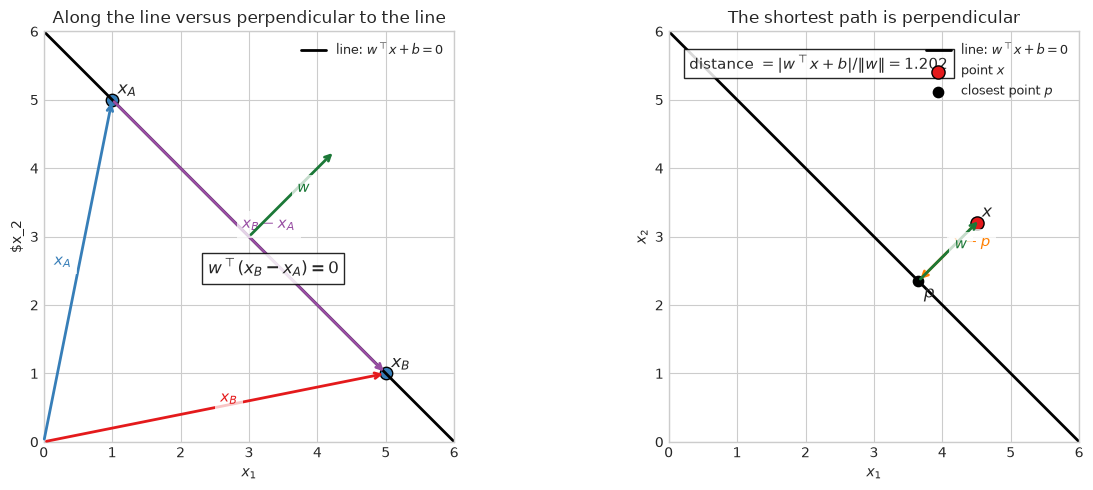

w dot (x_B - x_A) = 0.0
signed distance of x = 1.2020815280171309


In [4]:
# Visual proof: x_A and x_B point along the line; w points perpendicular to it.
def draw_hyperplane(ax, w, b, xlim=(0, 6), color="black", label=None, linestyle="-"):
    xs = np.linspace(*xlim, 300)
    ys = -(w[0] * xs + b) / w[1]
    ax.plot(xs, ys, color=color, linestyle=linestyle, label=label)

def arrow(ax, start, end, color, label, text_offset=(0.05, 0.05), linewidth=2):
    start, end = np.asarray(start), np.asarray(end)
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="->", color=color, linewidth=linewidth))
    middle = (start + end) / 2 + np.asarray(text_offset)
    ax.text(*middle, label, color=color, fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", alpha=.75))

w = np.array([1.0, 1.0])
b = -6.0
A = np.array([1.0, 5.0])
B = np.array([5.0, 1.0])
x = np.array([4.5, 3.2])
projection = x - ((w @ x + b) / (w @ w)) * w

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
xs = np.linspace(0, 6, 300)
ys = -(w[0] * xs + b) / w[1]

# Left: two points on the line and their position/direction vectors.
ax1.plot(xs, ys, color="black", linewidth=2, label=r"line: $w^\top x+b=0$")
ax1.scatter([A[0], B[0]], [A[1], B[1]], color="#377eb8", s=80, edgecolor="black")
ax1.text(*(A + [.08, .08]), r"$x_A$", fontsize=12)
ax1.text(*(B + [.08, .08]), r"$x_B$", fontsize=12)
arrow(ax1, np.zeros(2), A, "#377eb8", r"$x_A$", text_offset=(-.35, .08))
arrow(ax1, np.zeros(2), B, "#e41a1c", r"$x_B$", text_offset=(.08, .08))
arrow(ax1, A, B, "#984ea3", r"$x_B-x_A$", text_offset=(-.1, .12))
# w is drawn from the midpoint to make its perpendicular direction visible.
mid = (A + B) / 2
arrow(ax1, mid, mid + 1.25 * w, "#1b7837", r"$w$", text_offset=(.08, .02))
ax1.text(2.4, 2.45, r"$w^\top(x_B-x_A)=0$", fontsize=12,
         bbox=dict(facecolor="white", alpha=.85))
ax1.set(xlim=(0, 6), ylim=(0, 6), aspect="equal", xlabel=r"$x_1$", ylabel=r"$x_2",
        title="Along the line versus perpendicular to the line")
ax1.legend(fontsize=9, loc="upper right")

# Right: the shortest distance from x to the line is parallel to w.
ax2.plot(xs, ys, color="black", linewidth=2, label=r"line: $w^\top x+b=0$")
ax2.scatter(*x, color="#e41a1c", s=90, edgecolor="black", label=r"point $x$")
ax2.scatter(*projection, color="black", s=55, label=r"closest point $p$")
arrow(ax2, x, projection, "#ff7f00", r"$x-p$", text_offset=(.08, .08))
arrow(ax2, projection, projection + .9 * w, "#1b7837", r"$w$", text_offset=(.08, .02))
ax2.text(*(x + [.08, .08]), r"$x$", fontsize=12)
ax2.text(*(projection + [.08, -.25]), r"$p$", fontsize=12)
distance = abs(w @ x + b) / np.linalg.norm(w)
ax2.text(.3, 5.45, rf"distance $=|w^\top x+b|/\|w\|={distance:.3f}$",
         fontsize=11, bbox=dict(facecolor="white", alpha=.85))
ax2.set(xlim=(0, 6), ylim=(0, 6), aspect="equal", xlabel=r"$x_1$", ylabel=r"$x_2$",
        title="The shortest path is perpendicular")
ax2.legend(fontsize=9, loc="upper right")
plt.tight_layout(); plt.show()

print("w dot (x_B - x_A) =", w @ (B - A))
print("signed distance of x =", (w @ x + b) / np.linalg.norm(w))

## 4. From ordinary distance to the SVM margin

This section adds one missing step. We already know that the signed distance from a point $x$ to the decision line is

$$
d_{\pm}(x)=\frac{w^\top x+b}{\|w\|}.
$$

### Step 1: define the score of a point

For training example $i$, define

$$
\boxed{f_i=f(x_i)=w^\top x_i+b.}
$$

This number is called the **decision score**:

- $f_i>0$ means $x_i$ is on the positive side of the line;
- $f_i<0$ means $x_i$ is on the negative side;
- $f_i=0$ means $x_i$ is exactly on the line.

The signed distance is simply

$$
\frac{f_i}{\|w\|}=\frac{w^\top x_i+b}{\|w\|}.
$$

### Step 2: include the known label

Each training point has a label

$$
 y_i\in\{-1,+1\}.
$$

The label tells us which side is the **correct** side:

$$
\begin{array}{c|c|c}
\text{label} & \text{correct side} & \text{correct condition}\\
\hline
 y_i=+1 & f_i>0 & y_if_i>0\\
 y_i=-1 & f_i<0 & y_if_i>0
\end{array}
$$

For the negative class, multiplying by $y_i=-1$ flips a negative score into a positive number. Therefore define the distance measured toward the correct side as

$$
\boxed{\gamma_i(w,b)=y_i\frac{w^\top x_i+b}{\|w\|}.}
$$

This is the **geometric margin of training point $i$**. It is an objective-related quantity, not a new mysterious variable: once we choose $w$ and $b$, its value is determined.

For example, if $\|w\|=2$:

$$
\begin{array}{c|c|c|c}
y_i & f_i=w^\top x_i+b & f_i/\|w\| & y_if_i/\|w\|\\
\hline
+1 & +4 & +2 & +2\\
-1 & -4 & -2 & +2\\
\end{array}
$$

Both points are four score-units from the boundary and two geometric units on their correct sides. Without $y_i$, the negative-class point would incorrectly appear to have a negative margin even though it is correctly classified.

### Step 3: turn point margins into the margin of a line

A line is only as safe as its closest training point. Thus, for one fixed candidate $(w,b)$, define

$$
\boxed{\gamma_{\text{worst}}(w,b)=\min_i\gamma_i(w,b)
=\min_i y_i\frac{w^\top x_i+b}{\|w\|}.}
$$

The SVM chooses the line whose closest point is as far away as possible:

$$
\boxed{\max_{w,b}\;\gamma_{\text{worst}}(w,b)
=\max_{w,b}\;\min_i y_i\frac{w^\top x_i+b}{\|w\|}.}
$$

So the expression is an objective function of the candidate line $(w,b)$:

- the inner $\min$ finds the closest correctly oriented training point;
- the outer $\max$ chooses the line with the largest such distance.

Here $w^\top x$ means a dot product:

$$
w^\top x=\sum_{j=1}^d w_jx_j.
$$

The superscript $\top$ means “transpose.” It turns the column vector $w$ into a row vector so that the dot product with $x$ is defined.

## 5. From the two class inequalities to the SVM optimization problem

This is the complete bridge from the picture to the optimization problem.

### Step 1: require every point to be on the correct side

Recall the score

$$
f(x_i)=w^\top x_i+b.
$$

For a positive example, $y_i=+1$, the point should be on the positive side. To leave a safety gap, require

$$
w^\top x_i+b\ge 1.
$$

For a negative example, $y_i=-1$, the point should be on the negative side. Require

$$
w^\top x_i+b\le -1.
$$

Written separately:

$$
\begin{array}{ll}
y_i=+1: & w^\top x_i+b\ge1,\\[2mm]
y_i=-1: & w^\top x_i+b\le-1.
\end{array}
$$

### Step 2: write both inequalities with one formula

Multiply each inequality by its label $y_i$:

- If $y_i=+1$, nothing changes:
  $$w^\top x_i+b\ge1.$$
- If $y_i=-1$, multiplying by $-1$ reverses the inequality:
  $$w^\top x_i+b\le-1
  \quad\Longleftrightarrow\quad
  -(w^\top x_i+b)\ge1.$$

Thus both classes are represented by

$$
\boxed{y_i(w^\top x_i+b)\ge1.}
$$

This says: every point must have at least one unit of **functional margin** on its correct side.

### Step 3: why are the gutter values exactly $+1$ and $-1$?

The decision line itself is

$$
w^\top x+b=0.
$$

The numerical scale of $w$ and $b$ is arbitrary: multiplying both by any positive constant gives the same line. For example,

$$
w^\top x+b=0
\quad\text{and}\quad
(3w)^\top x+3b=0
$$

describe the same geometric line.

So we choose a convenient scale. Let

$$
m=\min_i y_i(w^\top x_i+b)>0
$$

be the smallest functional margin of a separating line. Divide $w$ and $b$ by $m$:

$$
\widetilde w=\frac{w}{m},
\qquad
\widetilde b=\frac{b}{m}.
$$

Then

$$
\min_i y_i(\widetilde w^\top x_i+\widetilde b)
=\frac{1}{m}\min_i y_i(w^\top x_i+b)=1.
$$

Therefore, without changing the line, we can always choose the scale so that the closest points satisfy

$$
 y_i(w^\top x_i+b)=1.
$$

That creates the two canonical gutters:

$$
\boxed{w^\top x+b=+1}
\qquad\text{and}\qquad
\boxed{w^\top x+b=-1}.
$$

### Step 4: convert the width into the objective

From the previous cell, the full distance between these gutters is

$$
\operatorname{width}=\frac{2}{\|w\|}.
$$

Therefore, the maximum-margin SVM wants

$$
\max_{w,b}\frac{2}{\|w\|}
\quad\text{subject to}\quad
 y_i(w^\top x_i+b)\ge1.
$$

The constant $2$ does not affect which $(w,b)$ is best, and $1/\|w\|$ is largest exactly when $\|w\|$ is smallest. Hence

$$
\max_{w,b}\frac{2}{\|w\|}
\quad\Longleftrightarrow\quad
\min_{w,b}\|w\|.
$$

Because $\|w\|\ge0$, minimizing $\|w\|$ is equivalent to minimizing its square. We include $\tfrac12$ only to simplify derivatives:

$$
\boxed{
\begin{aligned}
\min_{w,b}\quad &\frac12\|w\|^2\\
\text{subject to}\quad &y_i(w^\top x_i+b)-1\ge0,
\qquad i=1,\ldots,n.
\end{aligned}}
$$

This is the **hard-margin primal problem**. It is the exact mathematical version of: “find the separating line with the widest possible gutters.”

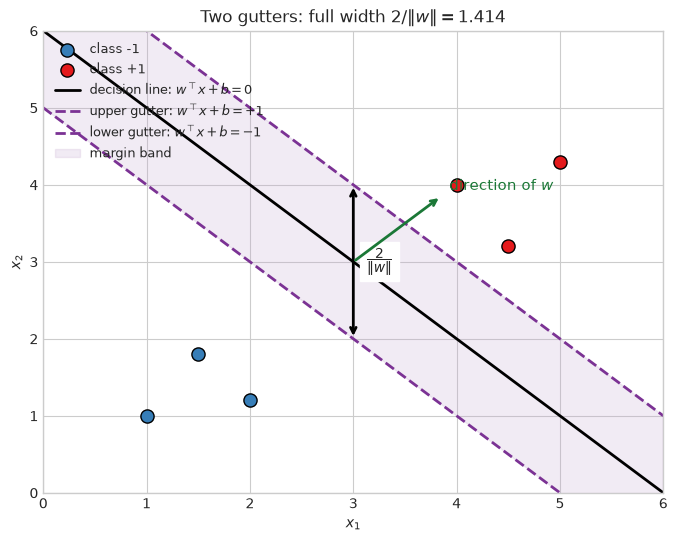

distance from decision line to either gutter = 0.7071067811865475
full gutter-to-gutter width = 1.414213562373095


In [3]:
# Visualize the decision line, both gutters, their normal vector, and their width.
w = np.array([1.0, 1.0])
b = -6.0
xs = np.linspace(0, 6, 300)
y0 = -(w[0] * xs + b) / w[1]
y_plus = -(w[0] * xs + b - 1) / w[1]   # w^T x + b = +1
y_minus = -(w[0] * xs + b + 1) / w[1]  # w^T x + b = -1

fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in [(-1, "#377eb8", "class -1"), (1, "#e41a1c", "class +1")]:
    pts = X_demo[y_demo == label]
    ax.scatter(pts[:, 0], pts[:, 1], s=90, c=color, label=name, edgecolor="black")

ax.plot(xs, y0, color="black", linewidth=2, label=r"decision line: $w^\top x+b=0$")
ax.plot(xs, y_plus, color="#7b3294", linestyle="--", linewidth=2,
        label=r"upper gutter: $w^\top x+b=+1$")
ax.plot(xs, y_minus, color="#7b3294", linestyle="--", linewidth=2,
        label=r"lower gutter: $w^\top x+b=-1$")
ax.fill_between(xs, y_minus, y_plus, color="#c2a5cf", alpha=.22, label="margin band")

# Choose perpendicular points on the two gutters at x-coordinate 3.
x_minus = np.array([3.0, -(w[0] * 3.0 + b + 1) / w[1]])
x_plus = np.array([3.0, -(w[0] * 3.0 + b - 1) / w[1]])
midpoint = (x_minus + x_plus) / 2
ax.annotate("", xy=x_plus, xytext=x_minus,
            arrowprops=dict(arrowstyle="<->", color="black", linewidth=2))
ax.text(midpoint[0] + .12, midpoint[1],
        r"$\frac{2}{\|w\|}$", fontsize=14, va="center", backgroundcolor="white")

# A normal-direction arrow shows why the shortest segment is perpendicular.
normal_step = 1.2 * w / np.linalg.norm(w)
ax.annotate("", xy=midpoint + normal_step, xytext=midpoint,
            arrowprops=dict(arrowstyle="->", color="#1b7837", linewidth=2))
ax.text(*(midpoint + normal_step + np.array([.08, .08])), r"direction of $w$",
        color="#1b7837", fontsize=11)

ax.set(xlim=(0, 6), ylim=(0, 6), xlabel=r"$x_1$", ylabel=r"$x_2$",
       title=rf"Two gutters: full width $2/\|w\|={2/np.linalg.norm(w):.3f}$")
ax.legend(loc="upper left", fontsize=9)
plt.show()
print("distance from decision line to either gutter =", 1 / np.linalg.norm(w))
print("full gutter-to-gutter width =", 2 / np.linalg.norm(w))

## 6. From the constrained primal problem to the Lagrangian

We now have a standard constrained minimization problem:

$$
\begin{aligned}
\min_{w,b}\quad &\frac12\|w\|^2\\
\text{subject to}\quad &g_i(w,b)=y_i(w^\top x_i+b)-1\ge0,
\qquad i=1,\ldots,n.
\end{aligned}
$$

The objective is

$$
f(w,b)=\frac12\|w\|^2,
$$

and each $g_i(w,b)$ measures how much point $i$ satisfies its required margin.

### Why introduce a multiplier?

For every constraint, introduce a nonnegative number

$$
\alpha_i\ge0.
$$

The number $\alpha_i$ will measure how strongly constraint $i$ matters at the optimum. Combine the objective and all constraints into one expression:

$$
\boxed{
\mathcal{L}(w,b,\alpha)
=f(w,b)-\sum_{i=1}^n\alpha_i g_i(w,b).
}
$$

Substitute $f$ and $g_i$:

$$
\begin{aligned}
\mathcal{L}(w,b,\alpha)
&=\frac12\|w\|^2
-\sum_{i=1}^n\alpha_i\left[y_i(w^\top x_i+b)-1\right].
\end{aligned}
$$

Expanding the brackets gives

$$
\boxed{
\mathcal{L}(w,b,\alpha)
=\frac12 w^\top w
-\sum_{i=1}^n\alpha_i y_i(w^\top x_i+b)
+\sum_{i=1}^n\alpha_i.
}
$$

### Why is there a minus sign?

For a feasible point, $g_i(w,b)\ge0$. Since $\alpha_i\ge0$,

$$
-\alpha_i g_i(w,b)\le0.
$$

Therefore, at every feasible point,

$$
\mathcal{L}(w,b,\alpha)\le f(w,b).
$$

If a point violates the margin constraint, then $g_i<0$, and

$$
-\alpha_i g_i>0,
$$

so the multiplier creates a penalty for that violation. The Lagrangian lets us study the objective and all constraints in one expression. The next step is to differentiate it with respect to the original variables $w$ and $b$.

## 7. Stationarity eliminates $w$ and $b$

At an optimum, differentiate the Lagrangian with respect to the primal variables and set the derivatives to zero.

$$
\begin{aligned}

\nabla_w\mathcal{L}
&=w-\sum_{i=1}^n\alpha_i y_i x_i=0,\\
\boxed{w=\sum_{i=1}^n\alpha_i y_i x_i}.
\end{aligned}
$$

For the intercept,

$$
\begin{aligned}
\frac{\partial\mathcal{L}}{\partial b}
&=-\sum_{i=1}^n\alpha_i y_i=0,\\
\boxed{\sum_{i=1}^n\alpha_i y_i=0}.
\end{aligned}
$$

Also,

$$
w^\top w=\left(\sum_i\alpha_i y_i x_i\right)^\top\left(\sum_j\alpha_j y_j x_j\right)
=\sum_i\sum_j\alpha_i\alpha_jy_iy_jx_i^\top x_j.
$$

After substitution and cancellation, the dual is

$$
\boxed{\begin{aligned}
\max_{\alpha}\quad & \sum_i\alpha_i-\frac12\sum_i\sum_j\alpha_i\alpha_jy_iy_jx_i^\top x_j\\
\text{subject to}\quad & \alpha_i\ge0,\\
& \sum_i\alpha_i y_i=0.
\end{aligned}}
$$

## 8. KKT conditions and the meaning of support vectors

The hard-margin Karush--Kuhn--Tucker conditions are:

$$
\begin{aligned}
&y_i(w^\top x_i+b)-1\ge0 &&\text{(primal feasibility)},\\
&\alpha_i\ge0 &&\text{(dual feasibility)},\\
&w=\sum_i\alpha_i y_i x_i,\quad \sum_i\alpha_i y_i=0 &&\text{(stationarity)},\\
&\boxed{\alpha_i[y_i(w^\top x_i+b)-1]=0} &&\text{(complementary slackness)}.
\end{aligned}
$$

The product equation implies

$$
\alpha_i=0
\quad\text{or}\quad
 y_i(w^\top x_i+b)=1.
$$

Only points exactly on a margin boundary can have $\alpha_i>0$. These are the **support vectors**. All other points have $\alpha_i=0$ and do not directly contribute to $w$.

For a support vector $x_k$,

$$
\boxed{b=y_k-w^\top x_k.}
$$

With multiple support vectors, average these values numerically for stability.

optimization success: True
alpha: [0.      0.      0.19512 0.      0.19512 0.     ]
w: [0.4878  0.39024] b: -2.4439
support-vector indices: [2 4]


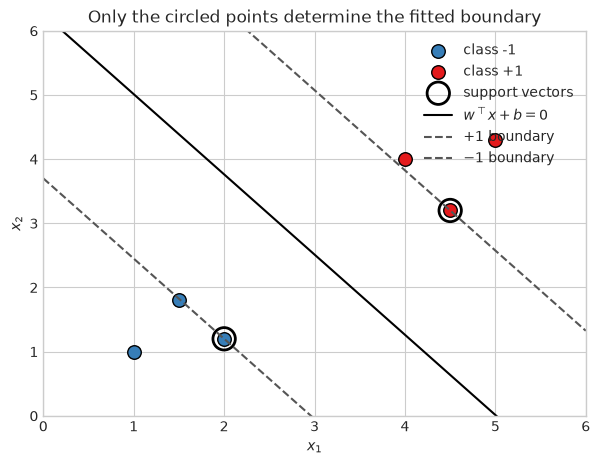

In [5]:
X = np.array([[1., 1.], [1.5, 1.8], [2., 1.2], [4., 4.], [4.5, 3.2], [5., 4.3]])
y = np.array([-1, -1, -1, 1, 1, 1.])
K = X @ X.T
Q = np.outer(y, y) * K
def dual_loss(alpha): return -(alpha.sum() - .5 * alpha @ Q @ alpha)
def dual_grad(alpha): return -(np.ones(len(alpha)) - Q @ alpha)
result = minimize(dual_loss, np.ones(len(y)) * .1, jac=dual_grad,
                  constraints={'type': 'eq', 'fun': lambda a: a @ y, 'jac': lambda a: y},
                  bounds=[(0, None)] * len(y), method='SLSQP', options={'ftol': 1e-12, 'maxiter': 1000})
alpha = result.x
w = (alpha * y) @ X
sv = alpha > 1e-5
b_values = y[sv] - X[sv] @ w
b = b_values.mean()
print('optimization success:', result.success)
print('alpha:', np.round(alpha, 5))
print('w:', np.round(w, 5), 'b:', round(b, 5))
print('support-vector indices:', np.flatnonzero(sv))
fig, ax = plt.subplots(figsize=(7, 5))
for label, color, name in [(-1, '#377eb8', 'class -1'), (1, '#e41a1c', 'class +1')]:
    pts = X[y == label]
    ax.scatter(pts[:, 0], pts[:, 1], s=95, c=color, label=name, edgecolor='black')
ax.scatter(X[sv, 0], X[sv, 1], s=260, facecolors='none', edgecolors='black', linewidths=2, label='support vectors')
draw_hyperplane(ax, w, b, xlim=(0, 6), label=r'$w^\top x+b=0$')
draw_hyperplane(ax, w, b + 1, xlim=(0, 6), color='#555', linestyle='--', label=r'$+1$ boundary')
draw_hyperplane(ax, w, b - 1, xlim=(0, 6), color='#555', linestyle='--', label=r'$-1$ boundary')
ax.set(xlim=(0, 6), ylim=(0, 6), xlabel=r'$x_1$', ylabel=r'$x_2$', title='Only the circled points determine the fitted boundary')
ax.legend(); plt.show()

## 9. Why kernels appear in the dual

The dual uses the data only through inner products:

$$
x_i^\top x_j.
$$

Map inputs into a feature space with $\phi:\mathbb{R}^d\to\mathcal{H}$. The linear SVM in that space has

$$
w=\sum_i\alpha_i y_i\phi(x_i)
$$

and

$$
f(x)=w^\top\phi(x)+b=\sum_i\alpha_i y_i\phi(x_i)^\top\phi(x)+b.
$$

Define

$$
\boxed{K(x_i,x_j)=\phi(x_i)^\top\phi(x_j)}.
$$

Then

$$
\boxed{f(x)=\sum_i\alpha_i y_iK(x_i,x)+b.}
$$

We never need to explicitly construct $\phi(x)$. Replacing every dot product by $K$ is the **kernel trick**. A valid kernel has a positive-semidefinite Gram matrix:

$$
z^\top Kz\ge0 \qquad\text{for every }z.
$$

## 10. Polynomial and RBF kernels: the transformation made visible

For the degree-two polynomial kernel

$$
K(x,z)=(x^\top z+c)^2,
$$

expansion for $x=(x_1,x_2)$ gives

$$
K(x,z)=x_1^2z_1^2+x_2^2z_2^2+2x_1x_2z_1z_2+2cx_1z_1+2cx_2z_2+c^2.
$$

One explicit feature map is

$$
\phi(x)=\left(x_1^2,x_2^2,\sqrt2x_1x_2,\sqrt{2c}x_1,\sqrt{2c}x_2,c\right).
$$

The radial basis function (Gaussian) kernel is

$$
\boxed{K(x,z)=\exp\left(-\frac{\|x-z\|^2}{2\sigma^2}\right)},
$$

or, equivalently,

$$
K(x,z)=\exp(-\gamma\|x-z\|^2),
\qquad \gamma=\frac{1}{2\sigma^2}.
$$

Large $\gamma$ produces very local influence and a more flexible boundary; small $\gamma$ produces smoother, more global influence.

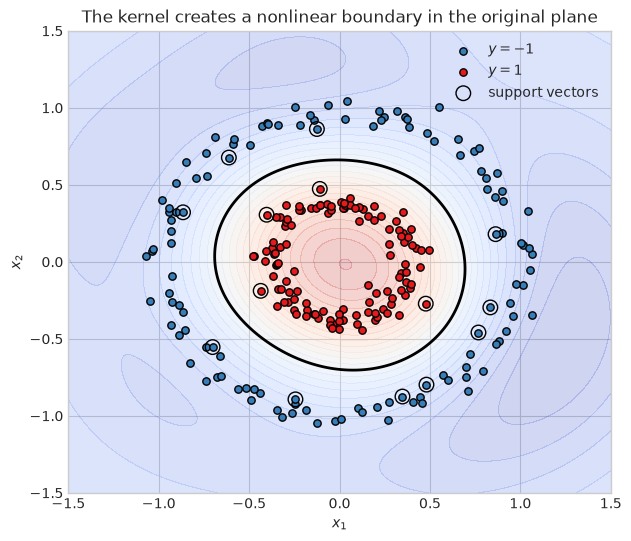

number of support vectors: 14


In [7]:
X_circle, y_circle = make_circles(n_samples=240, factor=.38, noise=.06, random_state=4)
y_circle = 2 * y_circle - 1
model = SVC(C=10, kernel='rbf', gamma='scale').fit(X_circle, y_circle)
grid_x, grid_y = np.meshgrid(np.linspace(-1.5, 1.5, 350), np.linspace(-1.5, 1.5, 350))
grid = np.c_[grid_x.ravel(), grid_y.ravel()]
score = model.decision_function(grid).reshape(grid_x.shape)
fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(grid_x, grid_y, score, levels=30, cmap='coolwarm', alpha=.25)
ax.contour(grid_x, grid_y, score, levels=[0], colors='black', linewidths=2)
for label, color in [(-1, '#377eb8'), (1, '#e41a1c')]:
    pts = X_circle[y_circle == label]
    ax.scatter(pts[:, 0], pts[:, 1], c=color, edgecolor='black', s=28, label=rf'$y={label}$')
ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=110, facecolors='none', edgecolors='black', label='support vectors')
ax.set(title='The kernel creates a nonlinear boundary in the original plane', xlabel=r'$x_1$', ylabel=r'$x_2$')
ax.legend(); plt.show()
print('number of support vectors:', len(model.support_))

## 11. When perfect separation is impossible: the soft-margin SVM

Real data may overlap or contain outliers. Introduce slack variables $\xi_i\ge0$:

$$
y_i(w^\top x_i+b)\ge1-\xi_i,
\qquad \xi_i\ge0.
$$

Interpretation:

$$
\begin{cases}
0\le\xi_i<1 &\text{correct side, but inside the margin},\\
\xi_i=1 &\text{on the decision boundary},\\
\xi_i>1 &\text{misclassified, since }y_if(x_i)<0.
\end{cases}
$$

Penalize violations with $C>0$:

$$
\boxed{\begin{aligned}
\min_{w,b,\xi}\quad &\frac12\|w\|^2+C\sum_i\xi_i\\
\text{subject to}\quad &y_i(w^\top x_i+b)\ge1-\xi_i,\\
&\xi_i\ge0.
\end{aligned}}
$$

Large $C$ heavily penalizes violations; small $C$ permits violations to obtain a wider margin.

## 12. Soft margin equals regularized hinge-loss minimization

For fixed $(w,b)$, the smallest feasible slack is

$$
\boxed{\xi_i^*=\max\left(0,1-y_i(w^\top x_i+b)\right).}
$$

Define hinge loss:

$$
\ell_{\text{hinge}}(y_i,f(x_i))=\max\left(0,1-y_if(x_i)\right).
$$

Substituting optimal slacks yields

$$
\boxed{\min_{w,b}\quad\frac12\|w\|^2+C\sum_i\max\left(0,1-y_i(w^\top x_i+b)\right).}
$$

Thus an SVM minimizes model complexity plus margin violations. Its hinge-loss subgradient with respect to $w$ is

$$
\partial_w\ell_i=\begin{cases}-y_ix_i,&y_if(x_i)<1,\\0,&y_if(x_i)>1,\\\text{any convex combination of }0\text{ and }-y_ix_i,&y_if(x_i)=1.\end{cases}
$$

## 13. The soft-margin dual and the complete kernelized model

Introduce multipliers $\alpha_i\ge0$ for the margin constraints and $\mu_i\ge0$ for $\xi_i\ge0$:

$$
\mathcal{L}=\frac12\|w\|^2+C\sum_i\xi_i-\sum_i\alpha_i[y_i(w^\top x_i+b)-1+\xi_i]-\sum_i\mu_i\xi_i.
$$

Stationarity gives

$$
w=\sum_i\alpha_i y_i x_i,
\qquad \sum_i\alpha_i y_i=0,
$$

and

$$
\frac{\partial\mathcal{L}}{\partial\xi_i}=C-\alpha_i-\mu_i=0
\quad\Longrightarrow\quad
0\le\alpha_i\le C.
$$

The soft-margin kernel dual is

$$
\boxed{\begin{aligned}
\max_{\alpha}\quad &\sum_i\alpha_i-\frac12\sum_i\sum_j\alpha_i\alpha_jy_iy_jK(x_i,x_j)\\
\text{subject to}\quad&0\le\alpha_i\le C,\\
&\sum_i\alpha_i y_i=0.
\end{aligned}}
$$

The final model is

$$
\boxed{f(x)=\sum_{i=1}^n\alpha_i y_iK(x_i,x)+b,\qquad \hat y(x)=\operatorname{sign}(f(x)).}
$$

## 14. How the model is trained and optimized

A practical training pipeline is:

1. Encode labels as $-1$ and $+1$.
2. Choose $K$, $C$, and possibly $\gamma$.
3. Build the Gram matrix $K_{ij}=K(x_i,x_j)$.
4. Solve
   $$\max_\alpha\;\mathbf{1}^\top\alpha-\frac12\alpha^\top Q\alpha,\qquad Q_{ij}=y_iy_jK_{ij}.$$
5. Keep points with $\alpha_i>0$ as support vectors.
6. Recover $b$ from points with $0<\alpha_i<C$:
   $$b=y_i-\sum_j\alpha_jy_jK(x_j,x_i).$$
7. Predict with
   $$\hat y(x)=\operatorname{sign}\left(\sum_i\alpha_iy_iK(x_i,x)+b\right).$$

Solvers such as sequential minimal optimization repeatedly optimize small subsets of multipliers while maintaining $\sum_i\alpha_i y_i=0$ and $0\le\alpha_i\le C$. For a valid kernel, the dual is convex optimization in the equivalent minimization form, so every optimum is global.

linear accuracy: 0.5138888888888888
RBF accuracy: 1.0
RBF support vectors: 13


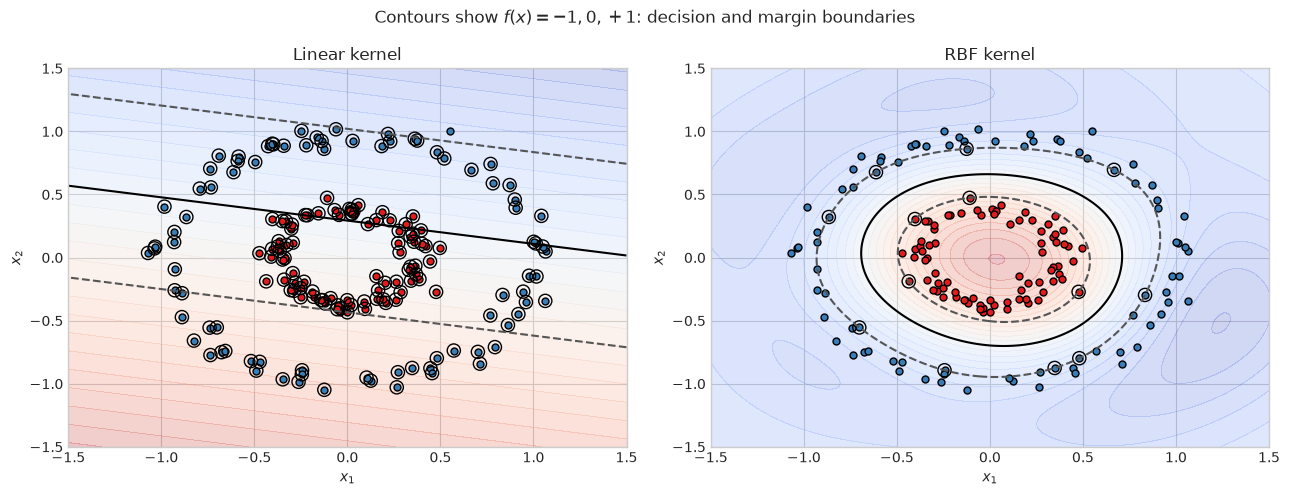

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X_circle, y_circle, test_size=.30, random_state=12, stratify=y_circle)
linear = SVC(C=1, kernel='linear').fit(X_train, y_train)
rbf = SVC(C=10, kernel='rbf', gamma='scale').fit(X_train, y_train)
print('linear accuracy:', accuracy_score(y_test, linear.predict(X_test)))
print('RBF accuracy:', accuracy_score(y_test, rbf.predict(X_test)))
print('RBF support vectors:', len(rbf.support_))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, fitted, title in [(axes[0], linear, 'Linear kernel'), (axes[1], rbf, 'RBF kernel')]:
    score = fitted.decision_function(grid).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, score, levels=30, cmap='coolwarm', alpha=.25)
    ax.contour(grid_x, grid_y, score, levels=[-1, 0, 1], colors=['#555', 'black', '#555'], linestyles=['--', '-', '--'])
    for label, color in [(-1, '#377eb8'), (1, '#e41a1c')]:
        pts = X_train[y_train == label]
        ax.scatter(pts[:, 0], pts[:, 1], c=color, edgecolor='black', s=25)
    ax.scatter(fitted.support_vectors_[:, 0], fitted.support_vectors_[:, 1], s=90, facecolors='none', edgecolors='black')
    ax.set(title=title, xlabel=r'$x_1$', ylabel=r'$x_2$', xlim=(-1.5, 1.5), ylim=(-1.5, 1.5))
plt.suptitle(r'Contours show $f(x)=-1,0,+1$: decision and margin boundaries')
plt.tight_layout(); plt.show()

## 15. Final summary: the entire derivation in one chain

Start with

$$f(x)=w^\top x+b,\qquad \hat y=\operatorname{sign}(f(x)).$$

The geometric margin is

$$\gamma_i=\frac{y_if(x_i)}{\|w\|}.$$

Normalize the closest functional margin to $1$:

$$\min_{w,b}\frac12\|w\|^2\quad\text{s.t.}\quad y_i(w^\top x_i+b)\ge1.$$

Lagrange stationarity gives

$$w=\sum_i\alpha_i y_i x_i,\qquad \sum_i\alpha_i y_i=0.$$

The dual depends only on dot products, so use

$$x_i^\top x_j\longrightarrow K(x_i,x_j).$$

Soft margins add

$$0\le\alpha_i\le C.$$

The trained kernel SVM predicts using only support vectors:

$$
\boxed{\hat y(x)=\operatorname{sign}\left(\sum_{i\in\mathrm{SV}}\alpha_i y_iK(x_i,x)+b\right).}
$$

This is the complete SVM: a maximum-margin geometric principle, expressed as a convex constrained optimization problem, solved through its Lagrange dual, and extended to nonlinear boundaries through kernels.